# A Predictive Model of Adverse Pregnancy Outcomes Among Malaria-Infected Pregnant Women in Resource-Constrained Settings using Explainable Boosting Machine

**Akpan Divine Eteyen (AK22/PHS/CSC/002)** — Department of Computer Science, Akwa Ibom State University

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve

from ebm_core import (
    DOMAIN_FEATURES,
    FEATURE_TO_DOMAIN,
    ALL_CANDIDATE_FEATURES,
    ComponentWiseGradientBoostingSelector,
    ExplainableBoostingMachineClassifier,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

DATA_DIR = "research_datasets"
DATA_PATH = os.path.join(DATA_DIR, "merged_malaria_pregnancy_outcomes_dataset.csv")
DICT_PATH = os.path.join(DATA_DIR, "merged_malaria_pregnancy_outcomes_dictionary.csv")
TOP20_DATA_PATH = os.path.join(DATA_DIR, "top_20_important_features_dataset.csv")
TOP20_DICT_PATH = os.path.join(DATA_DIR, "top_20_important_features_dictionary.csv")
MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
df_dict = pd.read_csv(DICT_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values: {int(df.isna().sum().sum())}")
for dom_name, dom_cols in DOMAIN_FEATURES.items():
    print(f"  - {dom_name:25s}: {len([c for c in dom_cols if c in df.columns]):3d} features")

df.head(5)

Dataset shape: 17,986 rows x 281 columns
Total missing values across entire dataset: 0

Candidate predictor counts by Proposed System Architecture domain:
  - Clinical/Maternal Data   :  47 features
  - Demographic Data         :  47 features
  - Lab Data                 :  11 features
  - Malaria Data             :  40 features


,woman_case_id,pregnancy_column_index,index_to_birth_history,cluster_number,household_number,respondent_line_number,child_line_number_in_household,womens_sample_weight,interview_month,interview_year,...,target_preterm_birth,target_preterm_delivery,target_lbw_measured,target_low_birth_weight_or_small_size,target_neonatal_death,target_perinatal_mortality,target_maternal_anemia,target_maternal_moderate_severe_anemia,target_any_adverse_pregnancy_outcome,target_any_apo_or_maternal_anemia
0,1 2 2,1,1,1,2,2,7,491963,1,2024,...,0,0,0,0,0,0,0,0,0,0
1,1 19 2,1,1,1,19,2,5,491963,1,2024,...,0,0,0,0,0,0,0,0,0,0
2,1 21 2,1,1,1,21,2,7,491963,1,2024,...,0,0,0,0,0,0,0,0,0,0
3,1 34 2,1,1,1,34,2,3,491963,1,2024,...,0,0,0,0,0,0,0,0,0,0
4,1 38 2,1,1,1,38,2,5,491963,1,2024,...,0,0,0,0,0,0,0,0,0,0


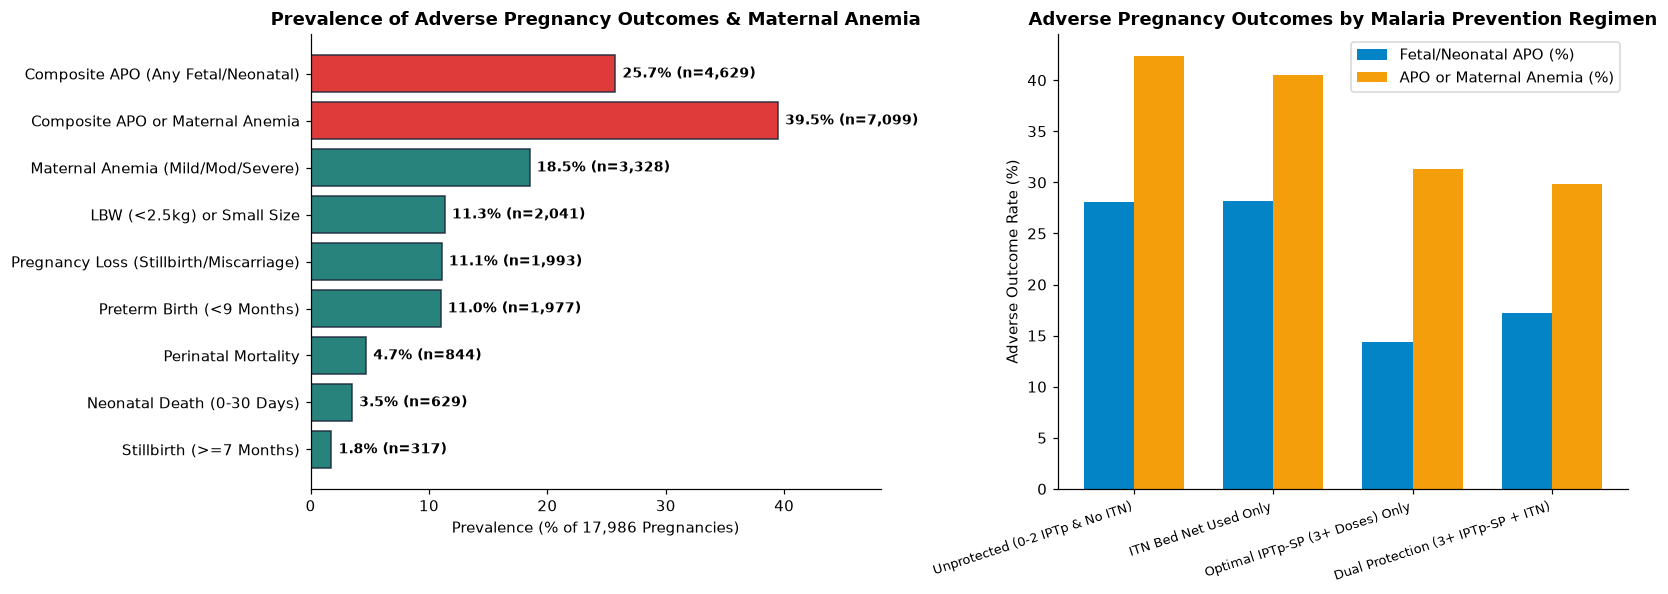

In [2]:
# Exploratory Data Analysis (EDA): Target Outcomes & Malaria Prevention Coverage
target_cols = {
    "Composite APO (Any Fetal/Neonatal)": "target_any_adverse_pregnancy_outcome",
    "Composite APO or Maternal Anemia": "target_any_apo_or_maternal_anemia",
    "Maternal Anemia (Mild/Mod/Severe)": "target_maternal_anemia",
    "LBW (<2.5kg) or Small Size": "target_low_birth_weight_or_small_size",
    "Pregnancy Loss (Stillbirth/Miscarriage)": "target_pregnancy_loss",
    "Preterm Birth (<9 Months)": "target_preterm_birth",
    "Perinatal Mortality": "target_perinatal_mortality",
    "Neonatal Death (0-30 Days)": "target_neonatal_death",
    "Stillbirth (>=7 Months)": "target_stillbirth",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Prevalence of Adverse Pregnancy Outcomes
names = list(target_cols.keys())[::-1]
counts = [int(df[target_cols[k]].sum()) for k in names]
pcts = [df[target_cols[k]].mean() * 100.0 for k in names]
colors = ["#dc2626" if "Composite" in n else "#0f766e" for n in names]

bars = axes[0].barh(names, pcts, color=colors, edgecolor="#1e293b", alpha=0.9)
axes[0].set_xlabel("Prevalence (% of 17,986 Pregnancies)")
axes[0].set_title("Prevalence of Adverse Pregnancy Outcomes & Maternal Anemia", fontweight="bold")
axes[0].set_xlim(0, max(pcts) * 1.22)
for bar, c, p in zip(bars, counts, pcts):
    axes[0].text(bar.get_width() + 0.6, bar.get_y() + bar.get_height() / 2,
                 f"{p:.1f}% (n={c:,})", va="center", fontsize=9, fontweight="bold")

# Plot 2: APO & Anemia Rate by Malaria Protection Status (IPTp-SP Doses & ITN Use)
prot_groups = pd.Series("Partial Protection (1-2 IPTp, No ITN)", index=df.index)
prot_groups[df["malaria_unprotected_in_pregnancy"] == 1] = "Unprotected (0-2 IPTp & No ITN)"
prot_groups[(df["malaria_iptp_optimal_3plus"] == 1) & (df["malaria_itn_slept_last_night"] == 0)] = "Optimal IPTp-SP (3+ Doses) Only"
prot_groups[(df["malaria_iptp_optimal_3plus"] == 0) & (df["malaria_itn_slept_last_night"] == 1)] = "ITN Bed Net Used Only"
prot_groups[(df["malaria_iptp_optimal_3plus"] == 1) & (df["malaria_itn_slept_last_night"] == 1)] = "Dual Protection (3+ IPTp-SP + ITN)"

grp_order = [
    "Unprotected (0-2 IPTp & No ITN)",
    "ITN Bed Net Used Only",
    "Optimal IPTp-SP (3+ Doses) Only",
    "Dual Protection (3+ IPTp-SP + ITN)",
]
apo_by_prot = [df.loc[prot_groups == g, "target_any_adverse_pregnancy_outcome"].mean() * 100 for g in grp_order]
anemia_by_prot = [df.loc[prot_groups == g, "target_any_apo_or_maternal_anemia"].mean() * 100 for g in grp_order]

x = np.arange(len(grp_order))
w = 0.36
axes[1].bar(x - w/2, apo_by_prot, width=w, label="Fetal/Neonatal APO (%)", color="#0284c7")
axes[1].bar(x + w/2, anemia_by_prot, width=w, label="APO or Maternal Anemia (%)", color="#f59e0b")
axes[1].set_xticks(x)
axes[1].set_xticklabels(grp_order, rotation=18, ha="right", fontsize=8.5)
axes[1].set_ylabel("Adverse Outcome Rate (%)")
axes[1].set_title("Adverse Pregnancy Outcomes by Malaria Prevention Regimen", fontweight="bold")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

In [3]:
# ==============================================================================
# STEP 2: DATA PREPROCESSING (Strict Train/Validation/Test Split BEFORE Scaling)
# ==============================================================================
candidate_cols = [c for c in ALL_CANDIDATE_FEATURES if c in df.columns]
PRIMARY_TARGET = "target_any_adverse_pregnancy_outcome"

X_all = df[candidate_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)
y_all = df[PRIMARY_TARGET].astype(int).to_numpy()

# Stratified 70% Train / 15% Validation / 15% Held-Out Test Split
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X_all, y_all, df.index.to_numpy(), test_size=0.30, random_state=42, stratify=y_all
)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Fit StandardScaler strictly on Training Data ONLY (No Data Leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=candidate_cols, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=candidate_cols, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=candidate_cols, index=X_test.index)

print(f"Training Set  : {X_train.shape[0]:,} pregnancies (Positive APO rate: {y_train.mean()*100:.2f}%)")
print(f"Validation Set: {X_val.shape[0]:,} pregnancies (Positive APO rate: {y_val.mean()*100:.2f}%)")
print(f"Test Set      : {X_test.shape[0]:,} pregnancies (Positive APO rate: {y_test.mean()*100:.2f}%)")

Training Set  : 12,590 pregnancies (Positive APO rate: 25.73%)
Validation Set: 2,698 pregnancies (Positive APO rate: 25.76%)
Test Set      : 2,698 pregnancies (Positive APO rate: 25.72%)


Selected strictly Top 20 features ranked by Feature Importance:
   1. number_of_pregnancy_losses (Clinical/Maternal Data)
   2. ever_had_terminated_pregnancy (Clinical/Maternal Data)
   3. number_of_living_children (Clinical/Maternal Data)
   4. children_under_5_in_household (Demographic Data)
   5. parity_total_children_ever_born (Clinical/Maternal Data)
   6. timing_first_anc_visit_months (Clinical/Maternal Data)
   7. malaria_iptp_doses (Malaria Data)
   8. multiple_or_twin_pregnancy (Clinical/Maternal Data)
   9. days_iron_tablets_or_syrup_taken (Clinical/Maternal Data)
  10. state_code (Demographic Data)
  11. tetanus_injections_before_birth (Clinical/Maternal Data)
  12. total_household_members (Demographic Data)
  13. preceding_pregnancy_interval_months (Clinical/Maternal Data)
  14. number_of_anc_visits (Clinical/Maternal Data)
  15. intestinal_parasite_drugs_during_pregnancy (Clinical/Maternal Data)
  16. malaria_iptp_optimal_3plus (Malaria Data)
  17. child_fever_last_2_weeks

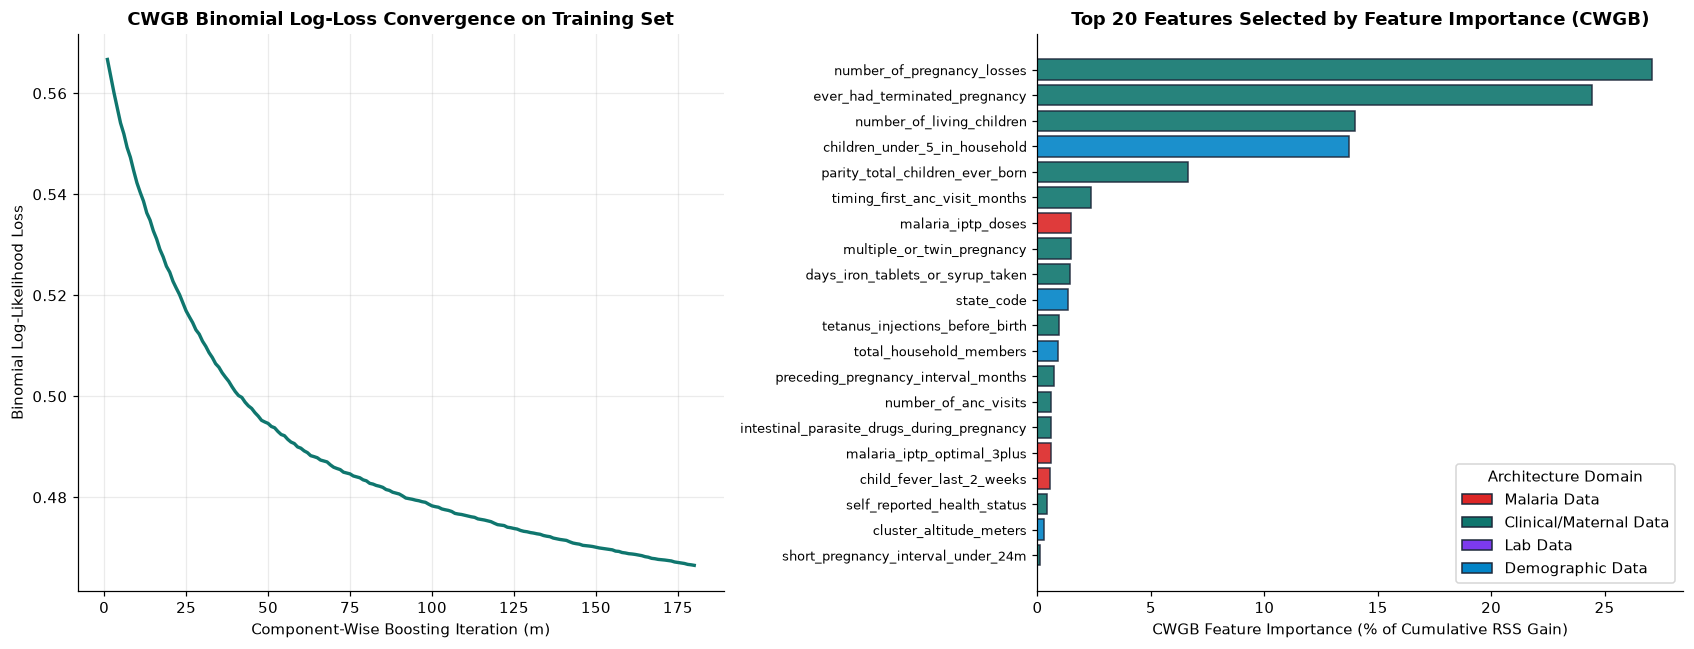

,feature_name,domain,selection_frequency,cumulative_rss_gain,relative_importance_pct,rank,selected_for_ebm
0,number_of_pregnancy_losses,Clinical/Maternal Data,22,1945.6857,27.103,1,True
1,ever_had_terminated_pregnancy,Clinical/Maternal Data,20,1754.1269,24.435,2,True
2,number_of_living_children,Clinical/Maternal Data,19,1003.4193,13.977,3,True
3,children_under_5_in_household,Demographic Data,20,985.3094,13.725,4,True
4,parity_total_children_ever_born,Clinical/Maternal Data,10,476.6708,6.640,5,True
5,timing_first_anc_visit_months,Clinical/Maternal Data,10,169.4244,2.360,6,True
6,malaria_iptp_doses,Malaria Data,7,107.2996,1.495,7,True
7,multiple_or_twin_pregnancy,Clinical/Maternal Data,10,106.0983,1.478,8,True
8,days_iron_tablets_or_syrup_taken,Clinical/Maternal Data,8,104.2940,1.453,9,True
9,state_code,Demographic Data,9,97.8252,1.363,10,True


In [4]:
# ==============================================================================
# STEP 3: COMPONENT-WISE GRADIENT BOOSTING FEATURE SELECTION (TOP 20)
# ==============================================================================
cwgb_selector = ComponentWiseGradientBoostingSelector(
    n_estimators=180,
    learning_rate=0.12,
    n_select=20,
    n_bins=12,
    l2_reg=5.0,
)
cwgb_selector.fit(X_train, y_train, domain_map=FEATURE_TO_DOMAIN)

selected_features = cwgb_selector.selected_features_
df_cwgb_rank = cwgb_selector.ranking_df_
df_cwgb_trace = pd.DataFrame(cwgb_selector.selection_trace_)

for rank_i, fname in enumerate(selected_features, 1):
    print(f"{rank_i:2d}. {fname} ({FEATURE_TO_DOMAIN.get(fname, 'Clinical')})")

df_cwgb_rank.to_csv(os.path.join(MODELS_DIR, "cwgb_feature_selection_results.csv"), index=False)

# Export the extracted 20-feature dataset and dictionary
TARGET_COLS = [
    "target_any_adverse_pregnancy_outcome",
    "target_any_apo_or_maternal_anemia",
    "target_maternal_anemia",
    "target_pregnancy_loss",
    "target_preterm_birth",
    "target_low_birth_weight_or_small_size",
    "target_neonatal_death",
]
df_top20 = df[selected_features + TARGET_COLS].apply(pd.to_numeric, errors="coerce")
df_top20 = df_top20.fillna(df_top20.median())
df_top20.to_csv(TOP20_DATA_PATH, index=False)

col_order = {c: i for i, c in enumerate(selected_features + TARGET_COLS)}
df_top20_dict = df_dict[df_dict["feature_name"].isin(col_order)].copy()
df_top20_dict["role"] = np.where(df_top20_dict["feature_name"].isin(selected_features), "Predictor", "Target")
df_top20_dict = df_top20_dict.sort_values("feature_name", key=lambda s: s.map(col_order))
df_top20_dict.to_csv(TOP20_DICT_PATH, index=False)

print(f"\nSaved {TOP20_DATA_PATH}: {df_top20.shape[0]:,} rows x {df_top20.shape[1]} columns, missing = {int(df_top20.isna().sum().sum())}")
print(f"Saved {TOP20_DICT_PATH}")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))

axes[0].plot(df_cwgb_trace["iteration"], df_cwgb_trace["log_loss"], color="#0f766e", linewidth=2.2)
axes[0].set_xlabel("Boosting Iteration (m)")
axes[0].set_ylabel("Binomial Log-Loss")
axes[0].set_title("CWGB Loss Convergence", fontweight="bold")
axes[0].grid(alpha=0.25)

top_sel = df_cwgb_rank[df_cwgb_rank["selected_for_ebm"]].sort_values("relative_importance_pct", ascending=True)
domain_palette = {
    "Malaria Data": "#dc2626",
    "Clinical/Maternal Data": "#0f766e",
    "Lab Data": "#7c3aed",
    "Demographic Data": "#0284c7",
}
bar_colors = [domain_palette.get(d, "#64748b") for d in top_sel["domain"]]
axes[1].barh(top_sel["feature_name"], top_sel["relative_importance_pct"], color=bar_colors, edgecolor="#1e293b", alpha=0.9)
axes[1].set_xlabel("Feature Importance (%)")
axes[1].set_title("Top 20 Features (CWGB)", fontweight="bold")
axes[1].tick_params(axis="y", labelsize=8.5)

from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor=c, edgecolor="#1e293b", label=d) for d, c in domain_palette.items()],
               loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

df_cwgb_rank.head(20)

In [5]:
# ==============================================================================
# STEP 4: EXPLAINABLE BOOSTING MACHINE (EBM / GA2M) & BASELINE MODEL TRAINING
# ==============================================================================
X_train_sel = cwgb_selector.transform(X_train)
X_val_sel = cwgb_selector.transform(X_val)
X_test_sel = cwgb_selector.transform(X_test)

scaler_sel = StandardScaler()
X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel)
X_val_sel_scaled = scaler_sel.transform(X_val_sel)
X_test_sel_scaled = scaler_sel.transform(X_test_sel)

# 1. Proposed Model: Explainable Boosting Machine (EBM / GA2M)
ebm_model = ExplainableBoostingMachineClassifier(
    n_cycles=95,
    learning_rate=0.035,
    n_bags=8,
    subsample=0.82,
    max_bins=24,
    n_interactions=8,
    interaction_rounds=45,
    interaction_bins=6,
    l2_reg=8.0,
    random_state=42,
)
ebm_model.fit(X_train_sel, y_train)

# 2. Baseline Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr_model.fit(X_train_sel_scaled, y_train)

# 3. Baseline Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1
)
rf_model.fit(X_train_sel, y_train)

# 4. Baseline Model 3: Standard Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.06, max_depth=3, random_state=42
)
gb_model.fit(X_train_sel, y_train)

# 5. Train Specific Endpoint EBM Sub-Models for Clinical Risk Breakdown in Streamlit
endpoint_targets = {
    "Composite APO or Maternal Anemia": "target_any_apo_or_maternal_anemia",
    "Maternal Anemia": "target_maternal_anemia",
    "Pregnancy Loss / Stillbirth": "target_pregnancy_loss",
    "Preterm Birth (<9 Months)": "target_preterm_birth",
    "Low Birth Weight (<2.5kg) / Small Size": "target_low_birth_weight_or_small_size",
    "Neonatal Mortality (0-30 Days)": "target_neonatal_death",
}
endpoint_ebm_models = {}
for ep_label, ep_col in endpoint_targets.items():
    y_ep_train = df.loc[idx_train, ep_col].astype(int).to_numpy()
    ep_ebm = ExplainableBoostingMachineClassifier(
        n_cycles=75, learning_rate=0.035, n_bags=6, n_interactions=4, random_state=42
    )
    ep_ebm.fit(X_train_sel, y_ep_train)
    endpoint_ebm_models[ep_label] = ep_ebm

print("Successfully trained Primary EBM (GA2M), 3 Baseline Models, and 6 Endpoint-Specific EBM Sub-Models!")
print(f"Detected Top Pairwise Interactions in Primary EBM:")
for k, (i, j) in enumerate(ebm_model.interactions_, 1):
    print(f"  {k}. {ebm_model.feature_names_in_[i]}  x  {ebm_model.feature_names_in_[j]}")

Successfully trained Primary EBM (GA2M), 3 Baseline Models, and 6 Endpoint-Specific EBM Sub-Models!
Detected Top Pairwise Interactions in Primary EBM:
  1. ever_had_terminated_pregnancy  x  timing_first_anc_visit_months
  2. number_of_pregnancy_losses  x  timing_first_anc_visit_months
  3. number_of_living_children  x  parity_total_children_ever_born
  4. ever_had_terminated_pregnancy  x  child_fever_last_2_weeks
  5. number_of_pregnancy_losses  x  child_fever_last_2_weeks
  6. number_of_pregnancy_losses  x  intestinal_parasite_drugs_during_pregnancy
  7. ever_had_terminated_pregnancy  x  intestinal_parasite_drugs_during_pregnancy
  8. ever_had_terminated_pregnancy  x  parity_total_children_ever_born


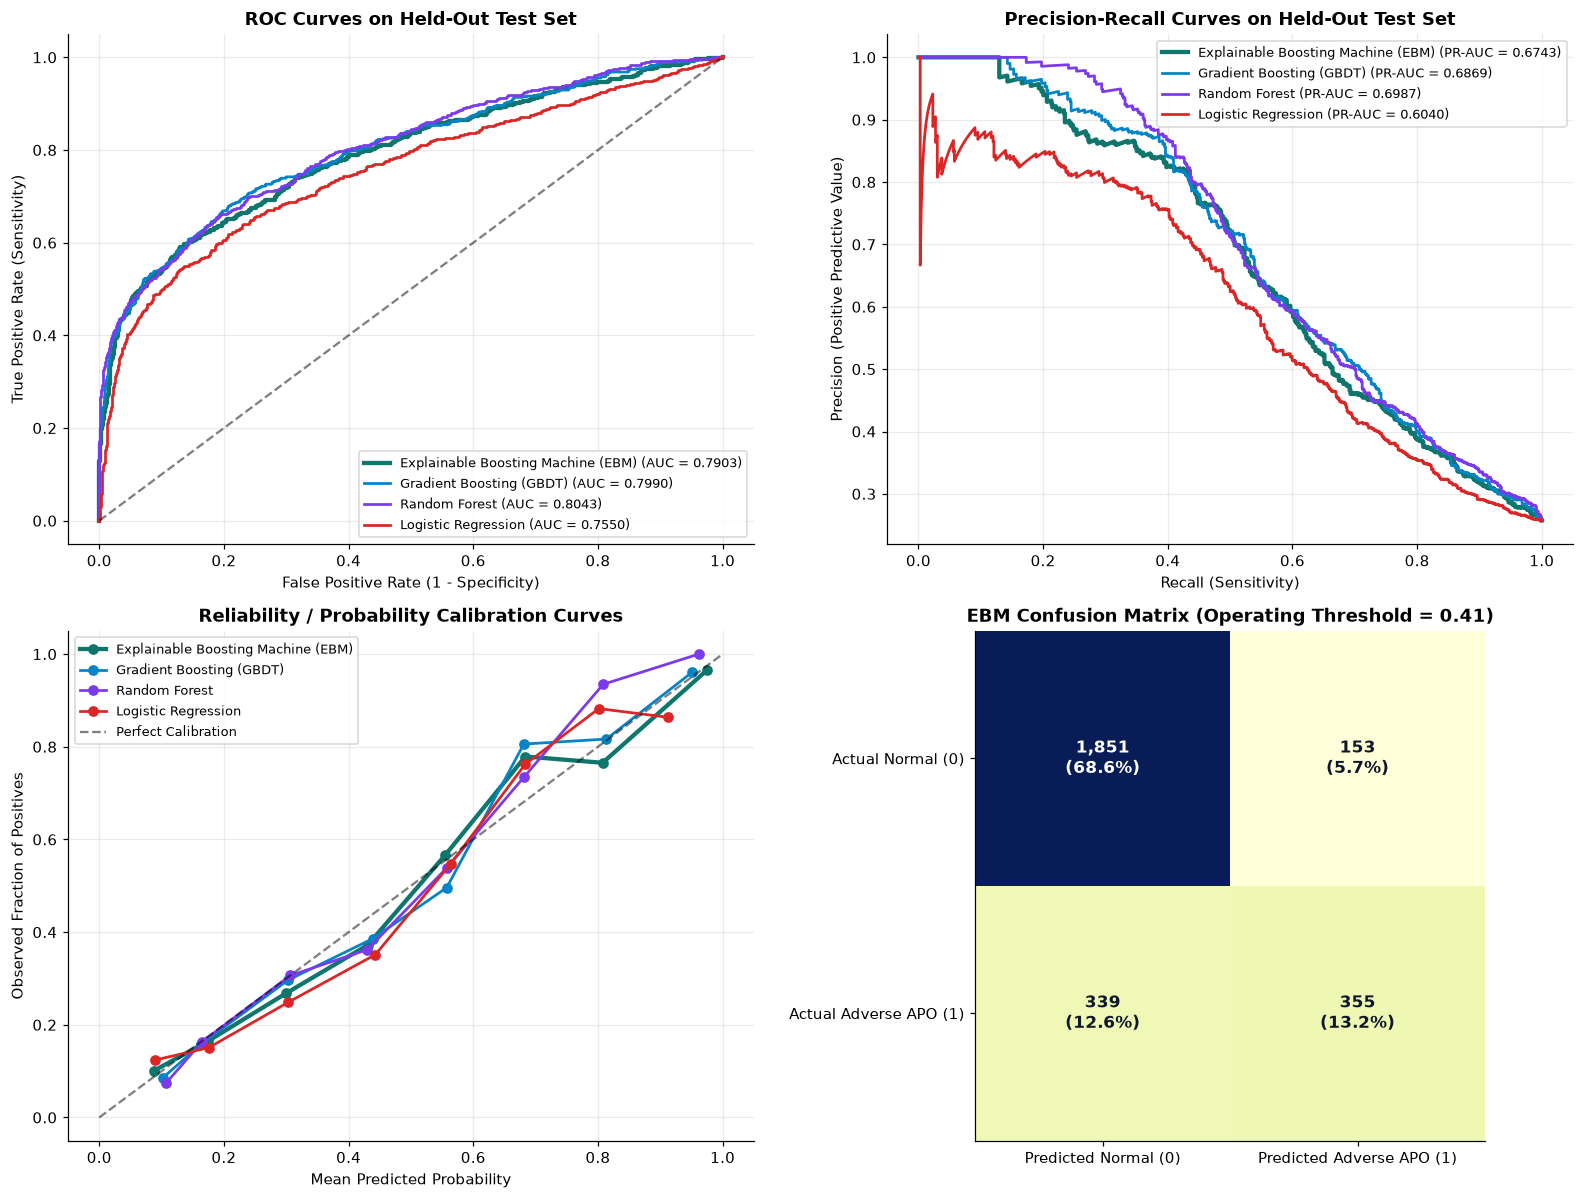

,Model,Accuracy,Precision,Sensitivity (Recall),Specificity,F1-Score,ROC-AUC,ROC-AUC 95% CI,PR-AUC,Brier Score
0,Explainable Boosting Machine (EBM),0.8176,0.6988,0.5115,0.9237,0.5907,0.7903,"[0.7685, 0.8086]",0.6743,0.1352
1,Gradient Boosting (GBDT),0.8188,0.6923,0.5317,0.9182,0.6015,0.7990,"[0.7790, 0.8166]",0.6869,0.1330
2,Random Forest,0.8221,0.7296,0.4899,0.9371,0.5862,0.8043,"[0.7840, 0.8213]",0.6987,0.1309
3,Logistic Regression,0.7895,0.6061,0.5187,0.8832,0.5590,0.7550,"[0.7303, 0.7743]",0.6040,0.1487


In [6]:
# ==============================================================================
# STEP 5: MODEL EVALUATION, BENCHMARKING & 95% BOOTSTRAP CONFIDENCE INTERVALS
# ==============================================================================
def compute_metrics_with_ci(y_true, y_prob, threshold=0.32, n_boot=200, seed=42):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)
    brier = brier_score_loss(y_true, y_prob)

    rng = np.random.RandomState(seed)
    boot_aucs = []
    n = len(y_true)
    for _ in range(n_boot):
        b_idx = rng.choice(n, size=n, replace=True)
        if len(np.unique(y_true[b_idx])) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_true[b_idx], y_prob[b_idx]))
    ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])

    return {
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Sensitivity (Recall)": round(rec, 4),
        "Specificity": round(spec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4),
        "ROC-AUC 95% CI": f"[{ci_low:.4f}, {ci_high:.4f}]",
        "PR-AUC": round(pr_auc, 4),
        "Brier Score": round(brier, 4),
    }

model_probs_test = {
    "Explainable Boosting Machine (EBM)": ebm_model.predict_proba(X_test_sel)[:, 1],
    "Gradient Boosting (GBDT)": gb_model.predict_proba(X_test_sel)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test_sel)[:, 1],
    "Logistic Regression": lr_model.predict_proba(X_test_sel_scaled)[:, 1],
}

# Tune optimal F1 operating threshold on Validation Set for EBM
val_probs_ebm = ebm_model.predict_proba(X_val_sel)[:, 1]
thresholds = np.linspace(0.20, 0.55, 36)
best_thresh = float(thresholds[np.argmax([f1_score(y_val, (val_probs_ebm >= t).astype(int)) for t in thresholds])])

eval_rows = []
for m_name, probs in model_probs_test.items():
    res = compute_metrics_with_ci(y_test, probs, threshold=best_thresh)
    res["Model"] = m_name
    eval_rows.append(res)

df_eval = pd.DataFrame(eval_rows)[
    ["Model", "Accuracy", "Precision", "Sensitivity (Recall)", "Specificity", "F1-Score", "ROC-AUC", "ROC-AUC 95% CI", "PR-AUC", "Brier Score"]
]
df_eval.to_csv(os.path.join(MODELS_DIR, "model_evaluation_comparison.csv"), index=False)

# Plot ROC Curves, Precision-Recall Curves, Calibration Curve, and EBM Confusion Matrix
fig, axes = plt.subplots(2, 2, figsize=(14.5, 11))
palette = {
    "Explainable Boosting Machine (EBM)": "#0f766e",
    "Gradient Boosting (GBDT)": "#0284c7",
    "Random Forest": "#7c3aed",
    "Logistic Regression": "#dc2626",
}

for m_name, probs in model_probs_test.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_v = roc_auc_score(y_test, probs)
    lw = 2.8 if "EBM" in m_name else 1.8
    axes[0, 0].plot(fpr, tpr, label=f"{m_name} (AUC = {auc_v:.4f})", color=palette[m_name], linewidth=lw)

    prec_c, rec_c, _ = precision_recall_curve(y_test, probs)
    ap_v = average_precision_score(y_test, probs)
    axes[0, 1].plot(rec_c, prec_c, label=f"{m_name} (PR-AUC = {ap_v:.4f})", color=palette[m_name], linewidth=lw)

    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=8)
    axes[1, 0].plot(prob_pred, prob_true, marker="o", label=m_name, color=palette[m_name], linewidth=lw)

axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 0].set_title("ROC Curves on Held-Out Test Set", fontweight="bold")
axes[0, 0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0, 0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0, 0].legend(loc="lower right", fontsize=8.5)
axes[0, 0].grid(alpha=0.25)

axes[0, 1].set_title("Precision-Recall Curves on Held-Out Test Set", fontweight="bold")
axes[0, 1].set_xlabel("Recall (Sensitivity)")
axes[0, 1].set_ylabel("Precision (Positive Predictive Value)")
axes[0, 1].legend(loc="upper right", fontsize=8.5)
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect Calibration")
axes[1, 0].set_title("Reliability / Probability Calibration Curves", fontweight="bold")
axes[1, 0].set_xlabel("Mean Predicted Probability")
axes[1, 0].set_ylabel("Observed Fraction of Positives")
axes[1, 0].legend(loc="upper left", fontsize=8.5)
axes[1, 0].grid(alpha=0.25)

# Confusion Matrix for EBM
cm_ebm = confusion_matrix(y_test, (model_probs_test["Explainable Boosting Machine (EBM)"] >= best_thresh).astype(int))
im = axes[1, 1].imshow(cm_ebm, cmap="Teal" if "Teal" in plt.colormaps() else "YlGnBu")
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_yticks([0, 1])
axes[1, 1].set_xticklabels(["Predicted Normal (0)", "Predicted Adverse APO (1)"])
axes[1, 1].set_yticklabels(["Actual Normal (0)", "Actual Adverse APO (1)"])
axes[1, 1].set_title(f"EBM Confusion Matrix (Operating Threshold = {best_thresh:.2f})", fontweight="bold")
for r in range(2):
    for c in range(2):
        axes[1, 1].text(c, r, f"{cm_ebm[r, c]:,}\n({cm_ebm[r, c]/len(y_test)*100:.1f}%)",
                        ha="center", va="center", fontsize=11, fontweight="bold",
                        color="white" if cm_ebm[r, c] > cm_ebm.max() * 0.55 else "#0f172a")

plt.tight_layout()
plt.show()

df_eval

In [7]:
# ==============================================================================
# STEP 6: SLICE-BASED SUBGROUP EVALUATION (Geopolitical Zones, South-South, Akwa Ibom, Rural/Urban)
# ==============================================================================
df_test_meta = df.loc[idx_test].copy()
df_test_meta["ebm_prob"] = model_probs_test["Explainable Boosting Machine (EBM)"]
df_test_meta["ebm_pred"] = (df_test_meta["ebm_prob"] >= best_thresh).astype(int)

zone_names = {
    1: "North Central",
    2: "North East",
    3: "North West",
    4: "South East",
    5: "South South (Study Focus)",
    6: "South West",
}

slice_rows = []
for z_code, z_label in zone_names.items():
    sub = df_test_meta[df_test_meta["geopolitical_zone"] == z_code]
    if len(sub) > 10 and sub[PRIMARY_TARGET].nunique() == 2:
        slice_rows.append({
            "Subpopulation Slice": f"Zone: {z_label}",
            "Test Sample Size (n)": len(sub),
            "Observed APO Rate (%)": round(sub[PRIMARY_TARGET].mean() * 100, 2),
            "Mean Predicted Risk (%)": round(sub["ebm_prob"].mean() * 100, 2),
            "ROC-AUC": round(roc_auc_score(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
            "PR-AUC": round(average_precision_score(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
            "Brier Score": round(brier_score_loss(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
        })

for res_code, res_label in [(1, "Residence: Urban"), (2, "Residence: Rural")]:
    sub = df_test_meta[df_test_meta["residence_urban_rural"] == res_code]
    slice_rows.append({
        "Subpopulation Slice": res_label,
        "Test Sample Size (n)": len(sub),
        "Observed APO Rate (%)": round(sub[PRIMARY_TARGET].mean() * 100, 2),
        "Mean Predicted Risk (%)": round(sub["ebm_prob"].mean() * 100, 2),
        "ROC-AUC": round(roc_auc_score(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
        "PR-AUC": round(average_precision_score(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
        "Brier Score": round(brier_score_loss(sub[PRIMARY_TARGET], sub["ebm_prob"]), 4),
    })

df_slices = pd.DataFrame(slice_rows)
df_slices.to_csv(os.path.join(MODELS_DIR, "subgroup_slice_evaluation.csv"), index=False)
df_slices

,Subpopulation Slice,Test Sample Size (n),Observed APO Rate (%),Mean Predicted Risk (%),ROC-AUC,PR-AUC,Brier Score
0,Zone: North Central,746,20.91,22.39,0.7681,0.5708,0.1289
1,Zone: North East,565,30.44,28.65,0.7372,0.6315,0.1689
2,Zone: North West,496,27.62,24.70,0.7514,0.6533,0.1509
3,Zone: South East,303,21.78,24.17,0.8528,0.7337,0.1063
4,Zone: South South (Study Focus),322,28.88,33.70,0.8913,0.8460,0.1033
5,Zone: South West,266,26.32,26.75,0.8106,0.7309,0.1233
6,Residence: Urban,1092,27.38,27.09,0.8181,0.7388,0.1281
7,Residence: Rural,1606,24.60,25.43,0.7686,0.6236,0.1399


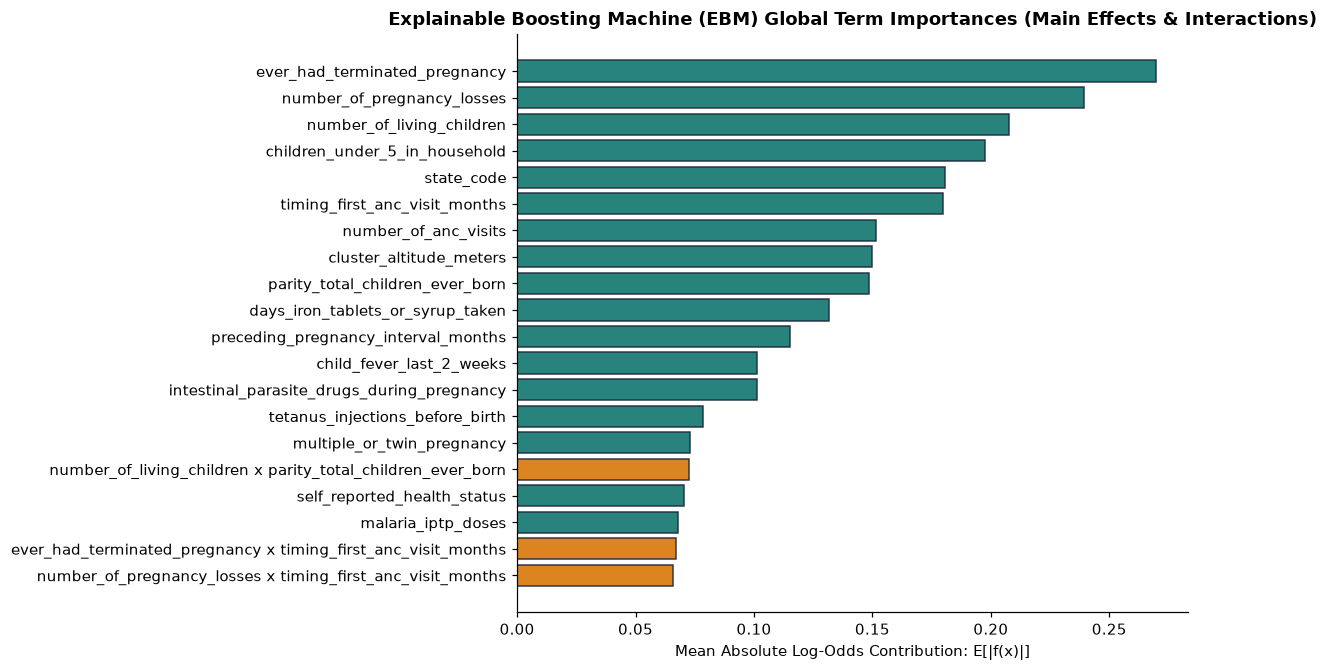

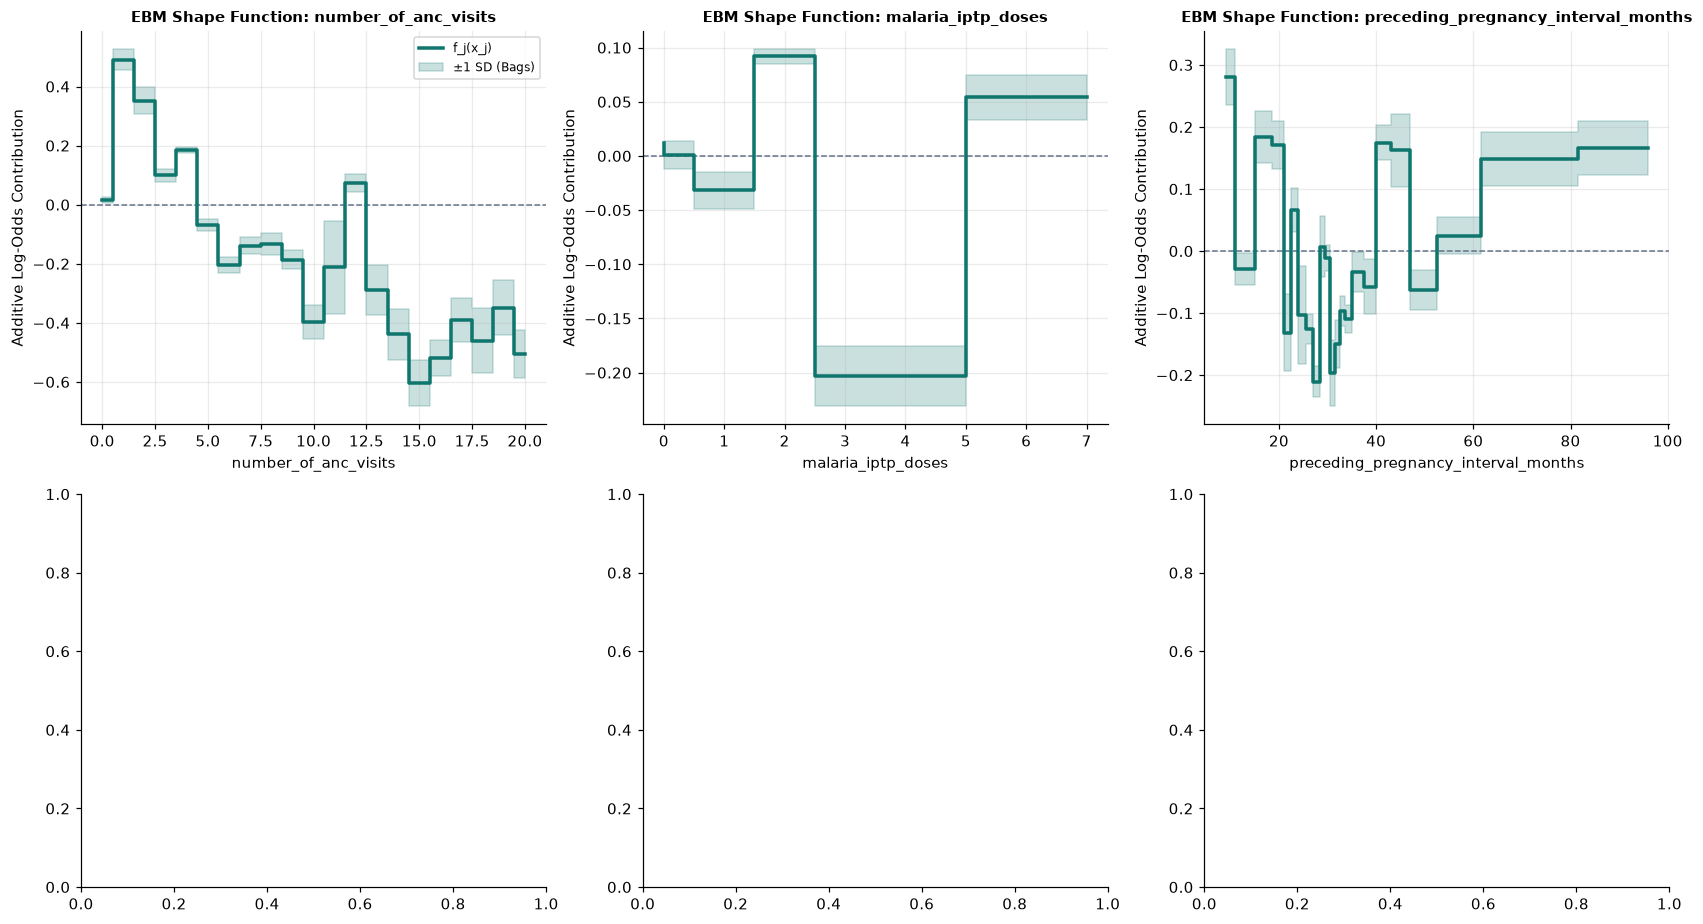

In [8]:
# ==============================================================================
# STEP 7: EBM GLOBAL EXPLAINABILITY — SHAPE FUNCTIONS f_j(x_j) & 2D INTERACTIONS
# ==============================================================================
df_global_imp = pd.DataFrame({
    "term": ebm_model.term_names_,
    "importance_mean_abs_log_odds": ebm_model.term_importances_,
    "type": ["Pairwise Interaction" if " x " in t else "Main Effect" for t in ebm_model.term_names_],
}).sort_values("importance_mean_abs_log_odds", ascending=False).reset_index(drop=True)
df_global_imp.to_csv(os.path.join(MODELS_DIR, "ebm_global_importances.csv"), index=False)

# Plot 1: Global Feature & Interaction Importance (Top 20 Terms)
fig, ax = plt.subplots(figsize=(11, 6.2))
top20 = df_global_imp.head(20).iloc[::-1]
colors_imp = ["#d97706" if t == "Pairwise Interaction" else "#0f766e" for t in top20["type"]]
ax.barh(top20["term"], top20["importance_mean_abs_log_odds"], color=colors_imp, edgecolor="#1e293b", alpha=0.9)
ax.set_xlabel("Mean Absolute Log-Odds Contribution: E[|f(x)|]")
ax.set_title("Explainable Boosting Machine (EBM) Global Term Importances (Main Effects & Interactions)", fontweight="bold")
plt.tight_layout()
plt.show()

# Plot 2: 1D Non-Linear EBM Shape Functions f_j(x_j) for 6 Key Clinical & Malaria Features
key_shape_features = [
    f for f in [
        "number_of_anc_visits",
        "malaria_iptp_doses",
        "maternal_hemoglobin_g_dl",
        "maternal_age_years",
        "maternal_bmi_kg_m2",
        "preceding_pregnancy_interval_months",
    ] if f in ebm_model.feature_names_in_
][:6]

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.5))
axes = axes.ravel()
for idx_p, fname in enumerate(key_shape_features):
    sdf = ebm_model.get_shape_function_df(fname)
    ax_s = axes[idx_p]
    ax_s.axhline(0.0, color="#64748b", linestyle="--", linewidth=1.0)
    ax_s.step(sdf["feature_value"], sdf["log_odds_score"], where="mid", color="#0f766e", linewidth=2.3, label="f_j(x_j)")
    ax_s.fill_between(sdf["feature_value"], sdf["lower_bound"], sdf["upper_bound"],
                      step="mid", color="#0f766e", alpha=0.22, label="±1 SD (Bags)")
    ax_s.set_title(f"EBM Shape Function: {fname}", fontweight="bold", fontsize=9.5)
    ax_s.set_xlabel(fname)
    ax_s.set_ylabel("Additive Log-Odds Contribution")
    ax_s.grid(alpha=0.25)
    if idx_p == 0:
        ax_s.legend(loc="best", fontsize=8)

plt.tight_layout()
plt.show()

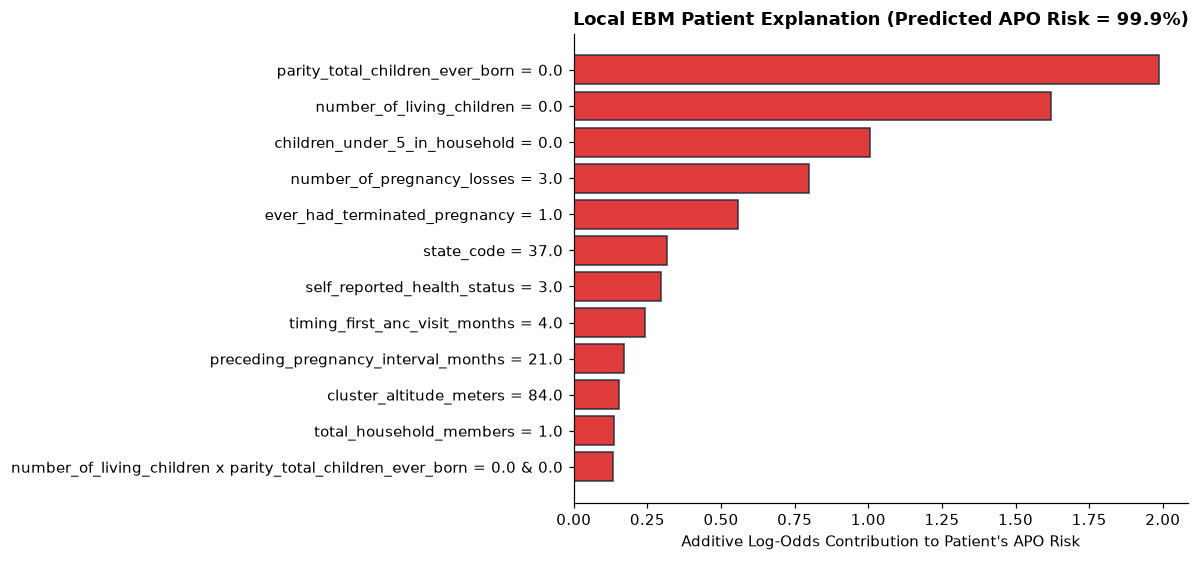

Saved complete EBM Model & Evaluation Bundle to: models\ebm_malaria_pregnancy_bundle.joblib


In [9]:
# ==============================================================================
# STEP 8: LOCAL PATIENT RESULT EXPLANATION & SERIALIZATION FOR STREAMLIT APP
# ==============================================================================
# Select a high-risk patient from the test set and generate an exact EBM local explanation
high_risk_idx = int(np.argmax(model_probs_test["Explainable Boosting Machine (EBM)"]))
sample_patient = X_test_sel.iloc[high_risk_idx]
local_exp = ebm_model.explain_local(sample_patient)

top_local = local_exp["contributions_df"].head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.2))
c_local = ["#dc2626" if v > 0 else "#16a34a" for v in top_local["log_odds_contribution"]]
bars = ax.barh(
    [f"{r['term']} = {r['patient_value']}" for _, r in top_local.iterrows()],
    top_local["log_odds_contribution"],
    color=c_local,
    edgecolor="#1e293b",
    alpha=0.9,
)
ax.axvline(0.0, color="#0f172a", linewidth=1.2)
ax.set_xlabel("Additive Log-Odds Contribution to Patient's APO Risk")
ax.set_title(
    f"Local EBM Patient Explanation (Predicted APO Risk = {local_exp['predicted_probability']*100:.1f}%)",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Compute default median/mode reference values for all selected features to power the Streamlit UI
feature_defaults = {}
feature_ranges = {}
for col in selected_features:
    s = X_train_sel[col]
    feature_defaults[col] = float(s.median())
    feature_ranges[col] = (float(s.min()), float(s.max()))

# Save the complete model & evaluation bundle for the Streamlit application (app.py)
bundle = {
    "ebm_model": ebm_model,
    "lr_model": lr_model,
    "rf_model": rf_model,
    "gb_model": gb_model,
    "endpoint_ebm_models": endpoint_ebm_models,
    "cwgb_selector": cwgb_selector,
    "scaler_sel": scaler_sel,
    "selected_features": selected_features,
    "feature_defaults": feature_defaults,
    "feature_ranges": feature_ranges,
    "best_threshold": best_thresh,
    "df_eval": df_eval,
    "df_slices": df_slices,
    "df_global_imp": df_global_imp,
    "df_cwgb_rank": df_cwgb_rank,
    "df_cwgb_trace": df_cwgb_trace,
}
bundle_path = os.path.join(MODELS_DIR, "ebm_malaria_pregnancy_bundle.joblib")
joblib.dump(bundle, bundle_path)
print(f"Saved complete EBM Model & Evaluation Bundle to: {bundle_path}")

In [10]:
# ==============================================================================
# STEP 9: LAUNCH STREAMLIT INTERFACE DIRECTLY FROM JUPYTER NOTEBOOK
# ==============================================================================
import subprocess
import sys
import time

streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
)
time.sleep(3)
print("✅ Streamlit Prototype Predictive System launched!")
print("👉 Click to open in your browser: http://localhost:8501")

✅ Streamlit Prototype Predictive System launched!
👉 Click to open in your browser: http://localhost:8501
